# Equity Returns, Risk Diagnostics, PCA & OLS Regression

**Author:** Antonio Rainis

**Course:** MSc Financial Data Science, UCD Smurfit Business School

## Executive summary

This notebook builds a small toolkit for comparing equity return series and applying two classic
techniques from empirical finance: **Principal Component Analysis (PCA)** for index decomposition
and **OLS regression** for cross-security dependence.

**Workflow**
1. Download and compare log returns for Stellantis (STLA) and Henkel (HEN3.DE).
2. Run standard risk diagnostics: descriptive statistics, correlation, distribution shape,
   stationarity (ADF), and outlier detection (boxplots + z-score filtering).
3. Decompose a 30-stock basket of Hang Seng Index constituents with PCA and build a
   first-principal-component-weighted portfolio, then compare it against the official HSI.
4. Fit an OLS regression of AT&T (T) returns on Shell (SHEL) returns and diagnose the residuals.

**Key findings**
- Stellantis is materially more volatile than Henkel (std. dev. ~2.5% vs ~1.3% daily), with a
  fatter tail on both sides of its return distribution, while both series are strongly stationary
  (ADF p-values ≈ 0).
- The two stocks show only a weak positive correlation (~0.33), so they offer meaningful
  diversification benefit if held together.
- Within a 30-name Hang Seng basket, **Ali Health (0241.HK)** and **Bank of China (3988.HK)**
  load most heavily on the first principal component, meaning they drive most of the common
  variance in the basket.
- A portfolio weighted by the (absolute) first-principal-component loadings returned roughly
  **+40%** cumulatively over 2019-2024, while the official HSI *lost* roughly **25%** over the same
  window — a reminder that PC-based weighting is a statistical construct, not automatically a
  better investable strategy, and the divergence here is largely a function of which 30 (of 50)
  constituents were sampled.
- Shell explains only about **13.7%** of the variance in AT&T's daily returns (R² = 0.137), and the
  residual diagnostics show the relationship is real (p ≈ 0) but far too noisy to be used as a
  standalone predictive signal.

**How to reproduce:** run all cells top to bottom. Requires an internet connection (Yahoo Finance
via `yfinance`). Chart PNGs are saved into a local `charts/` folder as each figure is produced.


In [1]:
import warnings
warnings.simplefilter(action='ignore', category=RuntimeWarning)

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from scipy import stats
from sklearn.decomposition import PCA

os.makedirs('charts', exist_ok=True)


## Helper functions

Small reusable helpers replace the repeated boilerplate from the original analysis (price plots,
ADF tests, and histograms were each duplicated 3-4 times).

In [4]:
def to_log_returns(price_series):
    """Convert a price series to log returns and drop the leading NaN."""
    return np.log(price_series / price_series.shift(1)).dropna()


def plot_price(series, label, color, title, filename=None):
    plt.figure()
    series.plot(label=label, color=color)
    plt.title(title)
    plt.ylabel('Price')
    plt.xlabel('Date')
    plt.legend()
    if filename:
        plt.savefig(f'charts/{filename}')
    plt.show()


def run_adf_test(series, name):
    result = adfuller(series)
    print(f'--- ADF test: {name} ---')
    print(f'ADF statistic: {result[0]:.6f}')
    print(f'p-value:       {result[1]:.6g}')
    print('Critical values:')
    for key, value in result[4].items():
        print(f'  {key}: {value:.3f}')
    verdict = 'stationary' if result[1] <= 0.05 else 'not stationary'
    print(f'Verdict (5% level): series is {verdict}\n')
    return result


def plot_return_histogram(series, label, color, bins, filename=None):
    plt.figure()
    plt.hist(series, bins=bins, label=label, color=color)
    plt.xlabel('Return')
    plt.ylabel('Density')
    plt.legend()
    if filename:
        plt.savefig(f'charts/{filename}')
    plt.show()


## 1. Stellantis vs Henkel: price history

Stellantis (STLA) is a global automaker; Henkel (HEN3.DE) is a German consumer goods /
adhesives group. Comparing an automaker with a consumer-staples name is a useful contrast in
cyclicality and volatility.

In [5]:
tickers = ['STLA', 'HEN3.DE']
stock_price = yf.download(tickers, start='2019-1-1', end='2024-12-31')['Close']
stock_price = pd.DataFrame(stock_price)
stock_price.head()


/var/folders/sk/9grpzxms3jl6cpnjz23m41_00000gn/T/ipykernel_17669/1669197663.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_price = yf.download(tickers, start='2019-1-1', end='2024-12-31')['Close']
[*********************100%***********************]  2 of 2 completed


Ticker,HEN3.DE,STLA
Date,,
2019-01-02,77.892616,7.671925
2019-01-03,76.997505,7.554142
2019-01-04,78.218132,8.025272
2019-01-07,77.339256,8.126994
2019-01-08,77.599670,8.212654


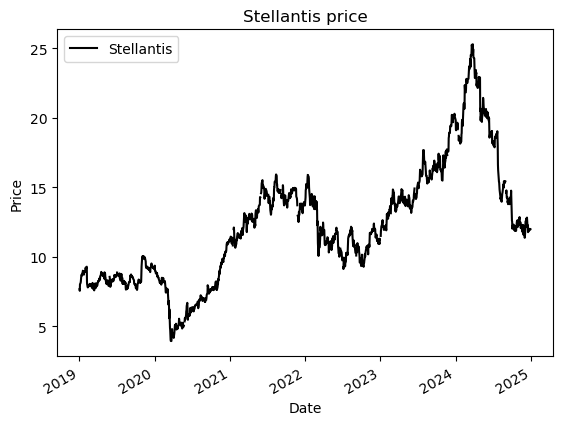

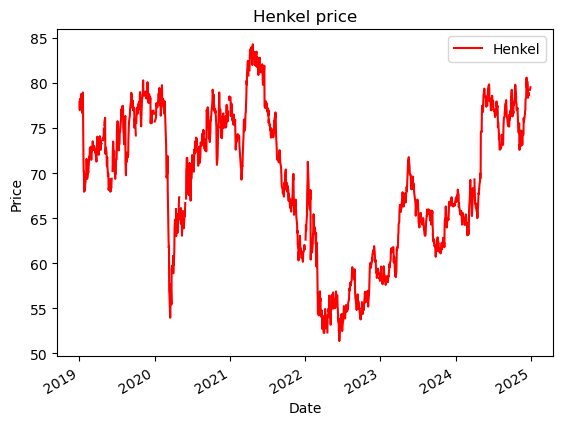

In [6]:
plot_price(stock_price['STLA'], 'Stellantis', 'black', 'Stellantis price', 'stla_price.png')
plot_price(stock_price['HEN3.DE'], 'Henkel', 'red', 'Henkel price', 'henkel_price.png')


Both series show high volatility. Stellantis rallied for roughly four years after the Covid-19
crash before turning lower on softer sales (six consecutive months of year-on-year declines).
Henkel, by contrast, is recovering off a bottom made in early 2022, after peaking in mid-2021 and
then entering a year-long bear phase to its lowest price in six years.

## 2. Convert to log returns and inspect

In [7]:
stock_price['STLA'] = to_log_returns(stock_price['STLA'])
stock_price['HEN3.DE'] = to_log_returns(stock_price['HEN3.DE'])
stock_price = stock_price.dropna()
stock_price.to_csv('stock_price.csv')
print(stock_price.head(5))
print(stock_price.tail(5))


Ticker       HEN3.DE      STLA
Date                          
2019-01-03 -0.011558 -0.015471
2019-01-04  0.015728  0.060500
2019-01-07 -0.011300  0.012596
2019-01-08  0.003362  0.010485
2019-01-09  0.014368  0.027645
Ticker       HEN3.DE      STLA
Date                          
2024-12-18 -0.014748 -0.041290
2024-12-19  0.001197  0.002339
2024-12-20  0.006442  0.003886
2024-12-23 -0.003812  0.001550
2024-12-30  0.003548 -0.002298


In [13]:
stock_price.describe()


Ticker,HEN3.DE,STLA
count,1424.000000,1424.000000
mean,0.000060,0.000208
std,0.013134,0.024792
min,-0.120263,-0.243794
25%,-0.006309,-0.011442
50%,0.000465,0.000858
75%,0.007475,0.013653
max,0.069677,0.109468


The mean daily return is slightly positive for both names, with Stellantis marginally ahead of
Henkel. Stellantis's much higher standard deviation, min, max, and interquartile range all confirm
the higher volatility from the automotive stock, but also the higher returning over the last 6 years

In [14]:
stock_price.corr()


Ticker,HEN3.DE,STLA
Ticker,,
HEN3.DE,1.000000,0.337406
STLA,0.337406,1.000000


A correlation of roughly 0.33 indicates a low, positive relationship: the two stock sometimes move together, but the link is not strong enough to treat them as substitutes.

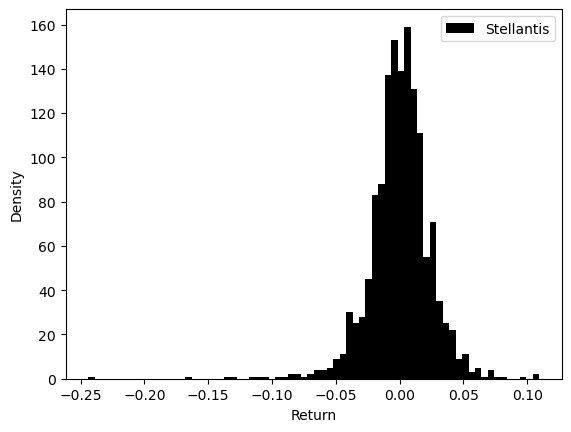

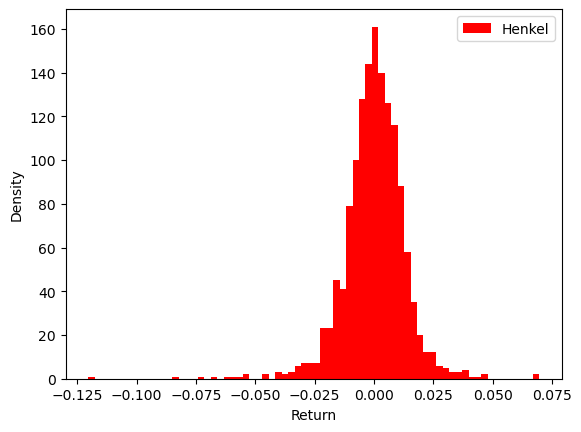

In [8]:
plot_return_histogram(stock_price['STLA'], 'Stellantis', 'black', 70, 'stla_hist.png')
plot_return_histogram(stock_price['HEN3.DE'], 'Henkel', 'red', 70, 'henkel_hist.png')


Both distributions are roughly bell-shaped and slightly left-skewed (frequent small positive
returns, occasional large negative ones), but Stellantis's distribution is visibly wider, with a
negative outlier near -0.25 versus about -0.125 for Henkel.

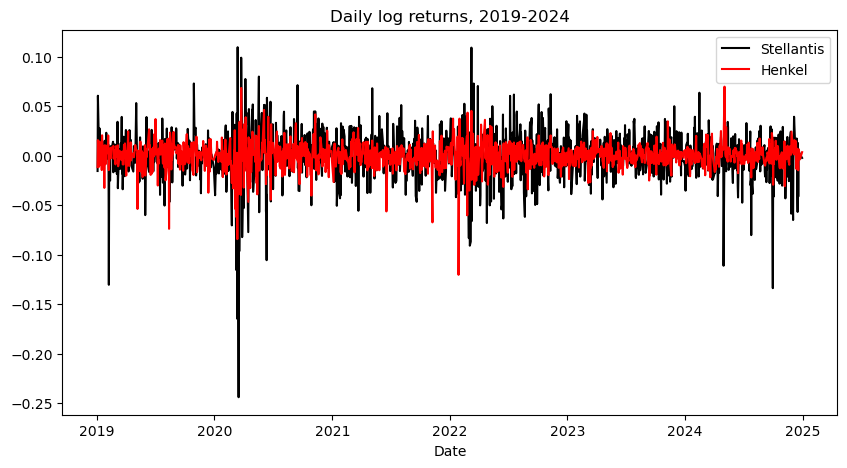

In [9]:
plt.figure(figsize=(10, 5))
plt.plot(stock_price['STLA'], label='Stellantis', color='black')
plt.plot(stock_price['HEN3.DE'], label='Henkel', color='red')
plt.xlabel('Date')
plt.title('Daily log returns, 2019-2024')
plt.legend()
plt.savefig('charts/returns_timeline.png')
plt.show()


Henkel's return path is visibly calmer, with fewer and smaller spikes than Stellantis, which
shows sharper moves in both directions — most notably around the 2020 crash and again with a large
positive Henkel return early in 2024 that coincided with a Stellantis drawdown.

## 3. Stationarity (ADF test)

In [10]:
_ = run_adf_test(stock_price['STLA'], 'Stellantis')
_ = run_adf_test(stock_price['HEN3.DE'], 'Henkel')


--- ADF test: Stellantis ---
ADF statistic: -8.327824
p-value:       3.43235e-13
Critical values:
  1%: -3.435
  5%: -2.864
  10%: -2.568
Verdict (5% level): series is stationary

--- ADF test: Henkel ---
ADF statistic: -15.647918
p-value:       1.60991e-28
Critical values:
  1%: -3.435
  5%: -2.864
  10%: -2.568
Verdict (5% level): series is stationary



Both ADF statistics are far below the 1% critical value (~-3.44), so both return series reject
the unit-root null decisively: the returns are stationary, as expected for daily equity returns.

## 4. Boxplots and outlier treatment

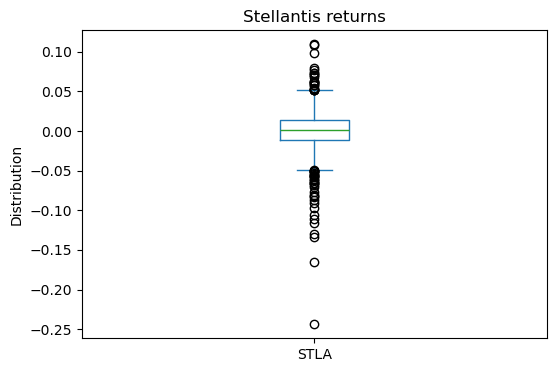

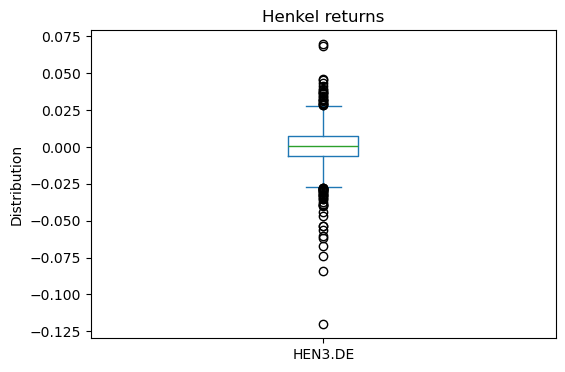

In [11]:
stock_price['STLA'].plot.box(title='Stellantis returns', ylabel='Distribution', figsize=(6, 4))
plt.savefig('charts/stla_box.png')
plt.show()

stock_price['HEN3.DE'].plot.box(title='Henkel returns', ylabel='Distribution', figsize=(6, 4))
plt.savefig('charts/henkel_box.png')
plt.show()


The Stellantis box spans roughly -0.05 to 0.05, about double Henkel's range, confirming the
higher volatility already seen above. Both series show a clear negative outlier (around -0.25 for
Stellantis, -0.125 for Henkel) plus a scatter of smaller potential outliers on both sides.

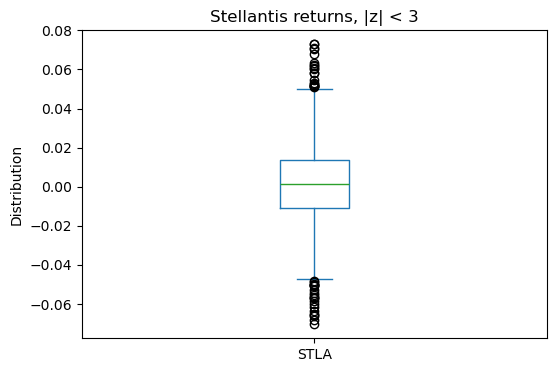

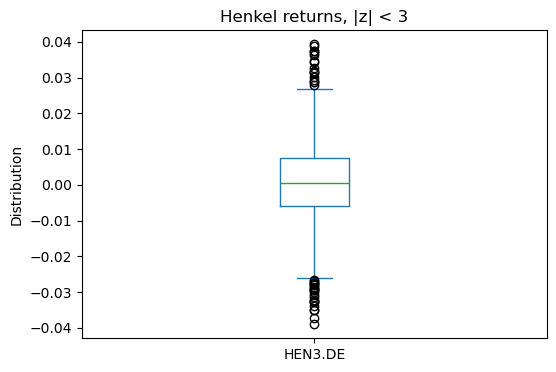

In [12]:
# NOTE: the original draft had a variable-name bug here (`numbers_Z` vs `z_numbers`)
# which raised a NameError on a fresh kernel run. Fixed below.
z_scores = np.abs(stats.zscore(stock_price))
no_outliers = stock_price[(z_scores < 3).all(axis=1)]

no_outliers['STLA'].plot.box(title='Stellantis returns, |z| < 3', ylabel='Distribution', figsize=(6, 4))
plt.savefig('charts/stla_box_filtered.png')
plt.show()

no_outliers['HEN3.DE'].plot.box(title='Henkel returns, |z| < 3', ylabel='Distribution', figsize=(6, 4))
plt.savefig('charts/henkel_box_filtered.png')
plt.show()


Even after removing points with |z| ≥ 3, Stellantis keeps a visibly wider interquartile range
and more dispersed whisker points than Henkel — the extra volatility is a persistent feature of the
stock, not just a couple of one-off outliers.

## 5. Hang Seng Index: PCA decomposition

The Hang Seng Index (HSI) tracks the largest ~50 names on the Hong Kong Stock Exchange, weighted
by free-float market cap, and represents roughly 60% of total exchange capitalisation. Here we
sample 30 of its constituents to study the common factor structure via PCA.

In [13]:
tickers_hsi = ['0241.HK', '1810.HK', '9988.HK', '0992.HK', '2319.HK',
               '1093.HK', '2628.HK', '3690.HK', '0003.HK', '6690.HK',
               '1109.HK', '9618.HK', '0700.HK', '0005.HK', '1299.HK',
               '1211.HK', '3988.HK', '0883.HK', '9999.HK', '0941.HK',
               '0939.HK', '1398.HK', '0388.HK', '0981.HK', '0688.HK',
               '0011.HK', '0669.HK', '0027.HK', '0175.HK', '2020.HK']

prices_hsi = yf.download(tickers_hsi, start='2019-1-1', end='2024-12-31')['Close']


/var/folders/sk/9grpzxms3jl6cpnjz23m41_00000gn/T/ipykernel_16796/1082286637.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices_hsi = yf.download(tickers_hsi, start='2019-1-1', end='2024-12-31')['Close']
[**********************47%                       ]  14 of 30 completedHTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: 0011.HK"}}}
[*********************100%***********************]  30 of 30 completed

1 Failed download:
['0011.HK']: YFTzMissingError('possibly delisted; no timezone found')


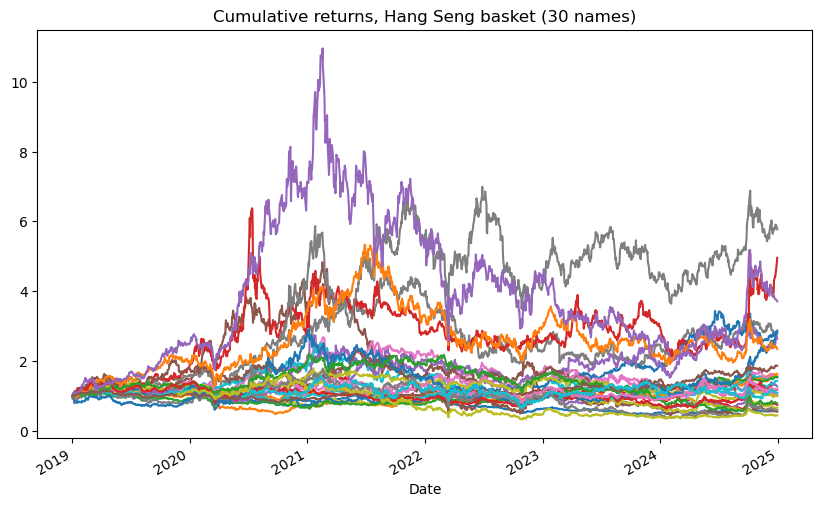

In [14]:
hsi_returns = prices_hsi.apply(np.log).diff(1)
hsi_returns.to_csv('HangSeng_returns.csv')

hsi_returns.cumsum().apply(np.exp).plot(legend=False, figsize=(10, 6),
                                         title='Cumulative returns, Hang Seng basket (30 names)')
plt.savefig('charts/hsi_cumulative_returns.png')
plt.show()


Two broad patterns emerge: a low-volatility cluster of names that stayed roughly flat over the
five years, and a higher-volatility cluster that rallied hard before giving back gains in the last
few years. All names show the shared Covid-19 dip in early 2020 followed by a rebound.

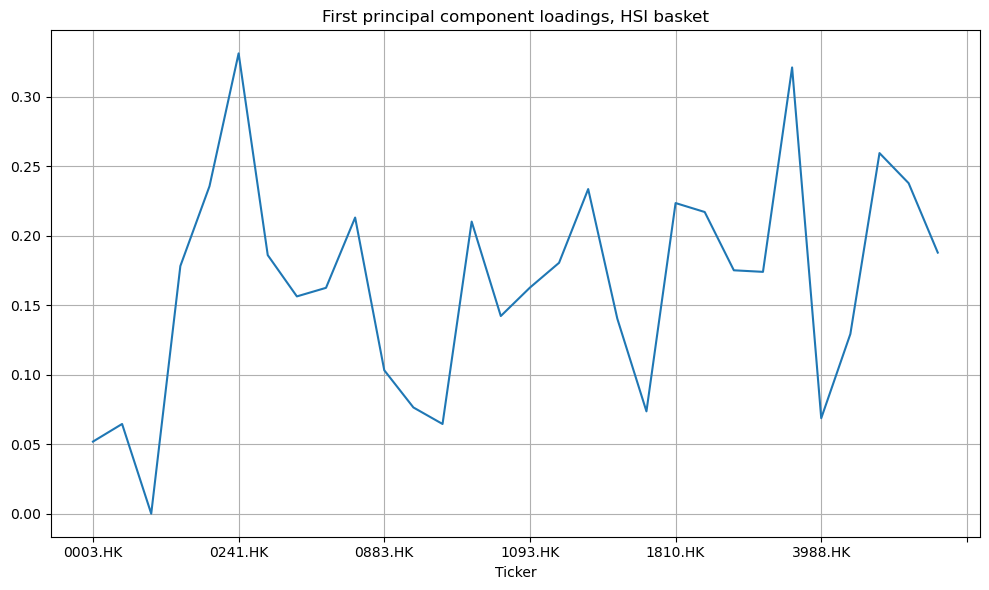

In [15]:
pca = PCA(n_components=1).fit(hsi_returns.fillna(0))
first_pc = pd.Series(index=hsi_returns.columns, data=pca.components_[0])

first_pc.plot(figsize=(10, 6), grid=True, title='First principal component loadings, HSI basket')
plt.tight_layout()
plt.savefig('charts/hsi_pca_loadings.png')
plt.show()


Ali Health (0241.HK, an Alibaba Group healthcare unit) carries the largest loading and is the
biggest driver of common variance in this basket, followed by Bank of China (3988.HK), CSPC
Pharmaceutical (1093.HK) and Xiaomi (1810.HK). Utility- and energy-type names such as Hong Kong &
China Gas (0003.HK) and CNOOC (0883.HK) load only weakly, i.e. they move more independently of the
common factor.

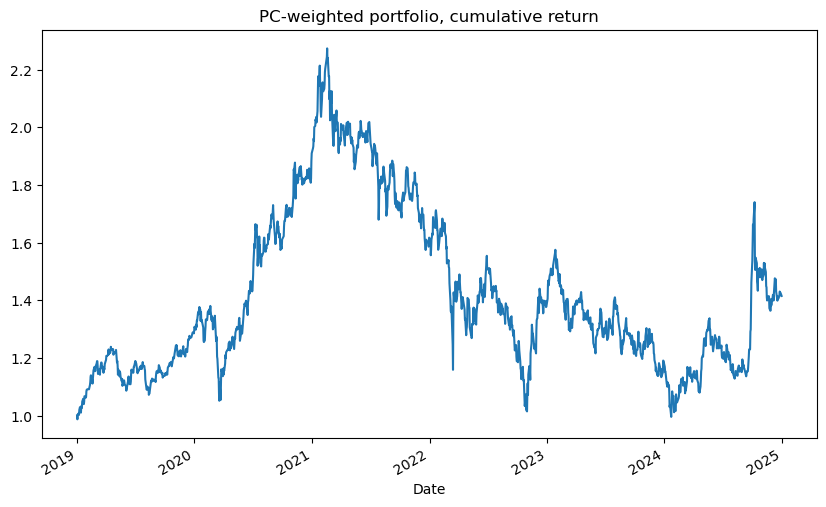

In [16]:
hsi_weights = first_pc.abs() / first_pc.abs().sum()
pc_weighted_return = (hsi_weights * hsi_returns).sum(axis=1)

pc_weighted_return.cumsum().apply(np.exp).plot(figsize=(10, 6), title='PC-weighted portfolio, cumulative return')
plt.savefig('charts/hsi_pc_portfolio.png')
plt.show()


A portfolio weighted by the absolute PC-1 loadings dips sharply in early 2020, then rallies to
an all-time high, before three years of drawdown and a partial 2024 recovery.

/var/folders/sk/9grpzxms3jl6cpnjz23m41_00000gn/T/ipykernel_16796/179792404.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  hsi_index = yf.download('^HSI', start='2019-1-1', end='2024-12-31')['Close']
[*********************100%***********************]  1 of 1 completed


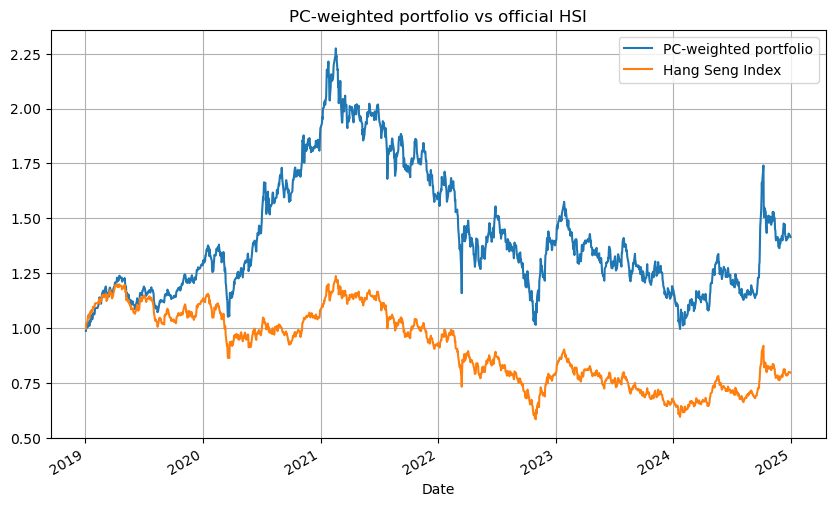

In [17]:
hsi_index = yf.download('^HSI', start='2019-1-1', end='2024-12-31')['Close']
index_returns = np.log(hsi_index / hsi_index.shift(1))
index_returns.to_csv('IndexReturns.csv')

portfolio = pd.concat([pc_weighted_return, index_returns], axis=1)
portfolio.columns = ['PC-weighted portfolio', 'Hang Seng Index']
portfolio.dropna().cumsum().apply(np.exp).plot(figsize=(10, 6), grid=True,
                                                title='PC-weighted portfolio vs official HSI')
plt.savefig('charts/hsi_portfolio_vs_index.png')
plt.show()


Over 2019-2024 the official HSI lost roughly 25% while the PC-weighted portfolio (built from
only 30 of the index's ~50 constituents) gained roughly 40%. The gap reflects both which names were
sampled and the fact that PC-1 weighting overweights the stocks that drive *variance*, not
necessarily the stocks that drove *returns* — the two happened to diverge sharply in this sample.

Both series shared the Covid-19 shock in early 2020, but the PC-weighted portfolio staged a
much sharper rebound, gaining over 100% from the 2020 low to its early-2021 peak, while the HSI
itself spent most of that year roughly flat before a multi-year decline.

## 6. AT&T vs Shell: correlation, distribution, and OLS regression

AT&T (T, telecoms) and Shell (SHEL, energy) are compared over a much longer window (2000-2024) to
see whether one helps explain the other.

/var/folders/sk/9grpzxms3jl6cpnjz23m41_00000gn/T/ipykernel_16796/7510202.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  en_tel_prices = yf.download(tickers_2, start='2000-1-1', end='2024-12-31')['Close']
[*********************100%***********************]  2 of 2 completed


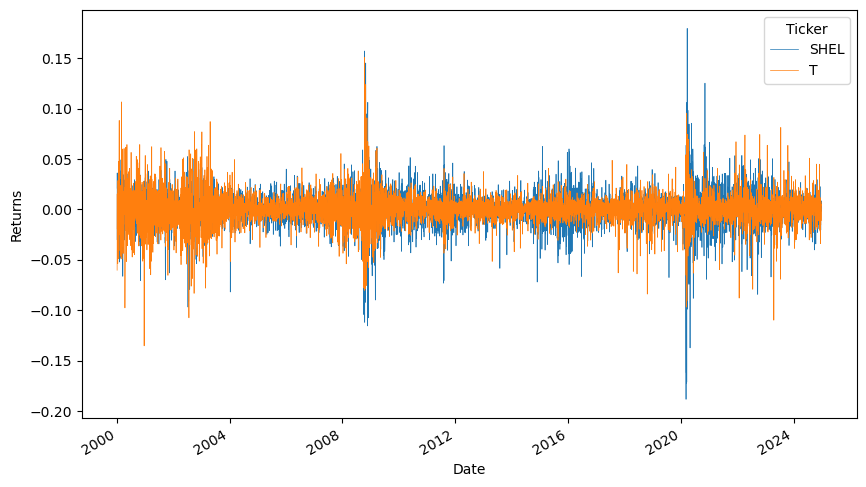

In [18]:
tickers_2 = ['T', 'SHEL']
en_tel_prices = yf.download(tickers_2, start='2000-1-1', end='2024-12-31')['Close']

en_tel_returns = np.log(en_tel_prices / en_tel_prices.shift(1)).dropna()
en_tel_returns.to_csv('EnergyTelecomReturns.csv')

en_tel_returns.plot(figsize=(10, 6), linewidth=0.5)
plt.xlabel('Date')
plt.ylabel('Returns')
plt.savefig('charts/att_shell_timeline.png')
plt.show()


AT&T was the more volatile of the two in the early 2000s (notably 2000-2004 and the Great
Recession); since then Shell has generally shown the sharper swings, especially during Covid-19,
when it posted some of its largest positive and negative daily moves.

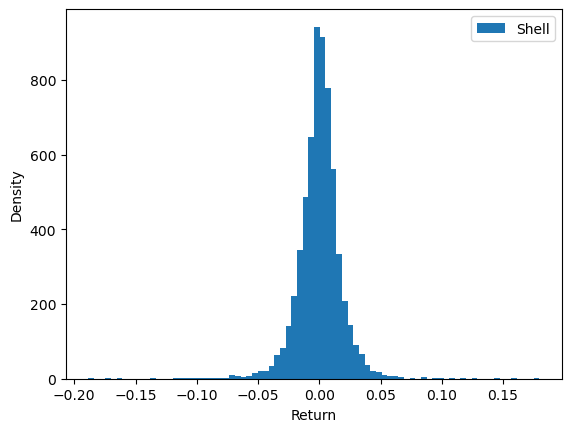

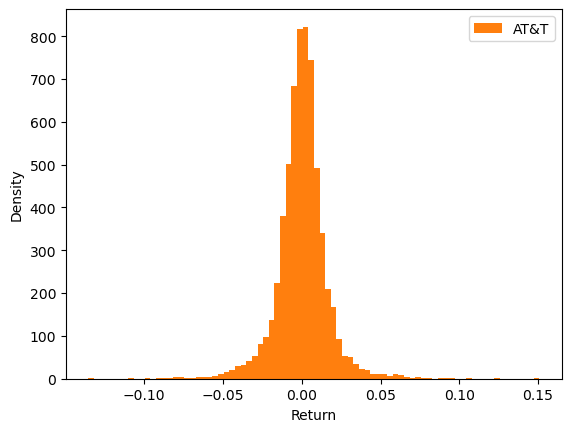

In [19]:
plot_return_histogram(en_tel_returns['SHEL'], 'Shell', 'tab:blue', 80, 'shell_hist.png')
plot_return_histogram(en_tel_returns['T'], 'AT&T', 'tab:orange', 80, 'att_hist.png')


Shell's return distribution is visibly wider than AT&T's, with stronger positive and negative
outliers, while AT&T's histogram looks close to a textbook normal shape with few outliers.

In [20]:
en_tel_returns.describe()


Ticker,SHEL,T
count,6287.000000,6287.000000
mean,0.000194,0.000196
std,0.018144,0.016171
min,-0.188406,-0.135376
25%,-0.008202,-0.007135
50%,0.000599,0.000507
75%,0.009036,0.007656
max,0.179647,0.150832


In [21]:
print(en_tel_returns.corr())
print(en_tel_returns.skew())
print(en_tel_returns.kurtosis())


Ticker      SHEL         T
Ticker                    
SHEL    1.000000  0.370778
T       0.370778  1.000000
Ticker
SHEL   -0.488778
T      -0.060049
dtype: float64
Ticker
SHEL    12.789277
T        7.545100
dtype: float64


The two names are only weakly correlated (~0.37). Shell's skew is meaningfully negative
(more/larger negative surprises), while AT&T's is close to zero (roughly symmetric). Both series
show excess kurtosis well above 3 (12.8 for Shell, 7.5 for AT&T), confirming fat tails and frequent
extreme moves relative to a normal distribution — Shell more so than AT&T.

In [22]:
regression = smf.ols(formula='T ~ SHEL', data=en_tel_returns)
results_ols = regression.fit()
print(results_ols.summary())


                            OLS Regression Results                            
Dep. Variable:                      T   R-squared:                       0.137
Model:                            OLS   Adj. R-squared:                  0.137
Method:                 Least Squares   F-statistic:                     1002.
Date:                Thu, 29 Oct 2026   Prob (F-statistic):          3.92e-204
Time:                        12:29:28   Log-Likelihood:                 17476.
No. Observations:                6287   AIC:                        -3.495e+04
Df Residuals:                    6285   BIC:                        -3.493e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0001      0.000      0.695      0.4

The R² of 0.137 means Shell's returns explain only about 13.7% of the variation in AT&T's
returns — a real but modest relationship. The F-test is highly significant (Shell's coefficient
p-value ≈ 0), while the intercept is not significantly different from zero (p = 0.487). Residual
skew of -0.25 and kurtosis of 10.3 both indicate the regression residuals themselves are
non-normal, with a mild left skew and a high chance of extreme values on both sides.

In [23]:
residuals = results_ols.resid
residuals.tail()


Date
2024-12-23    0.000995
2024-12-24    0.003164
2024-12-26    0.000735
2024-12-27   -0.006269
2024-12-30   -0.011610
dtype: float64

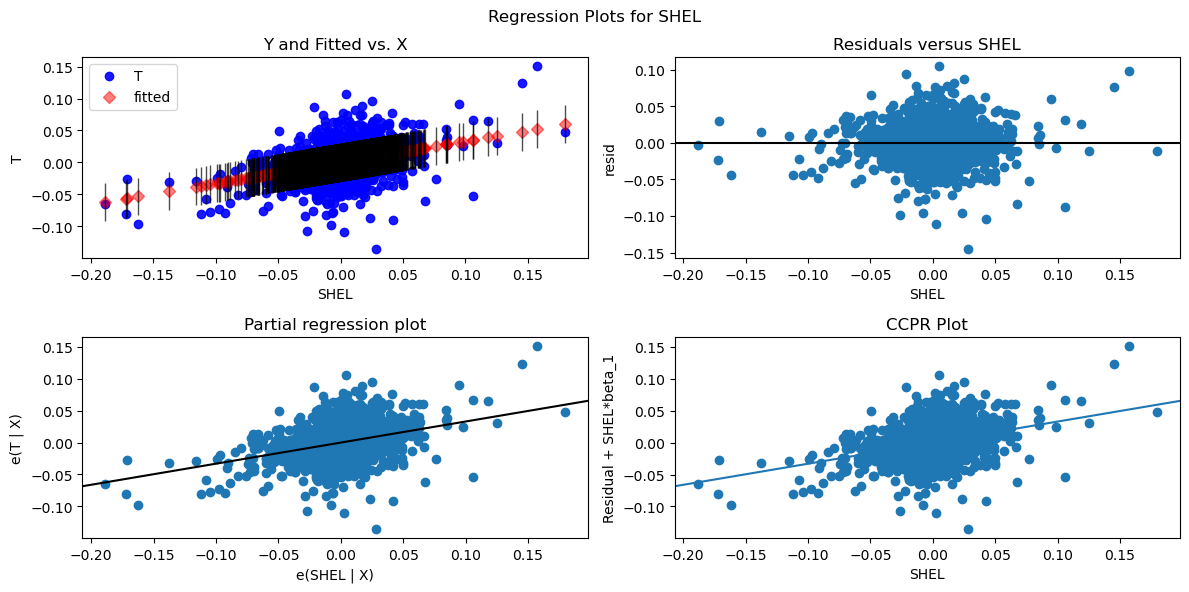

In [24]:
fig = plt.figure(figsize=(12, 6))
sm.graphics.plot_regress_exog(results_ols, 'SHEL', fig=fig)
plt.savefig('charts/att_shell_regression_diagnostics.png')
plt.show()


The four-panel diagnostic confirms the story: the fitted-vs-actual plot shows AT&T's returns
have plenty of variation that Shell alone cannot explain; the residuals-vs-Shell plot shows a
non-uniform spread (Shell is a real but limited driver); the partial regression plot confirms a
genuinely positive slope; and the CCPR plot shows that positive relationship persists but with
substantial scatter around it, consistent with the low R².